Question 1: Which product categories and articles are particularly often combined by customers in the same transaction and what significant association rules can be derived from this for cross-selling?

1. Setup & Data Loading

Load the two relevant data mart tables: `fact_sales` (one row per order line)
and `dim_products` (product master data incl. category). The category is needed
later to build category-level baskets.

In [2]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from collections import Counter

# Plot styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Load data mart tables
BASE = "/home/jovyan/work/Admin/Download_Data/Datamart_Tables/CSV/"
fact_sales   = pd.read_csv(BASE + "datamart_fact_sales.csv")
dim_products = pd.read_csv(BASE + "datamart_dim_products.csv")

# Quick shape check
print("fact_sales  :", fact_sales.shape)
print("dim_products:", dim_products.shape)
fact_sales.head(3)

fact_sales  : (181759, 11)
dim_products: (29120, 10)


,order_item_id,order_id,user_id,product_id,date_key,created_at,status,sale_price,inventory_cost,gross_margin,is_returned
0,56364,38797,31076,4699,2023-08-09,2023-08-09 05:40:12+00:00,Complete,69.99,35.83,34.16,0
1,165379,113915,90974,16626,2021-10-02,2021-10-02 00:32:36+00:00,Complete,19.99,11.85,8.14,0
2,6614,4584,3624,401,2021-10-09,2021-10-09 02:54:32+00:00,Processing,19.99,11.87,8.12,0


2. Data Preparation

Join each order line to its product category (`fact_sales` × `dim_products` on
`product_id`). Then keep only real purchases by removing cancelled/returned
lines via both the `status` column and the `is_returned` flag.

In [2]:
# Add category to each order line (fact x dim_products on product_id)
items = fact_sales.merge(
    dim_products[["product_id", "category", "department"]],
    on="product_id", how="left"
)

# Inspect order status distribution
print(items["status"].value_counts(dropna=False), "\n")

# Keep only actual purchases:
#  - drop cancelled / returned via status
#  - additionally require is_returned == 0 (return flag from the data mart)
exclude = ["Cancelled", "Returned"]
items_clean = items[(~items["status"].isin(exclude)) & (items["is_returned"] == 0)].copy()

status
Shipped       54440
Complete      45609
Processing    36388
Cancelled     27090
Returned      18232
Name: count, dtype: int64 



In [ ]:
3. Build Baskets

For each order, collect the set of distinct categories (a category counts once
per order). Orders with >= 2 categories are the ones that carry cross-selling
signal — single-category orders cannot form a pair.

Total orders:                  94,087
Avg. categories per order:     1.41
Orders with >=2 categories:    26,758 (28.4%)


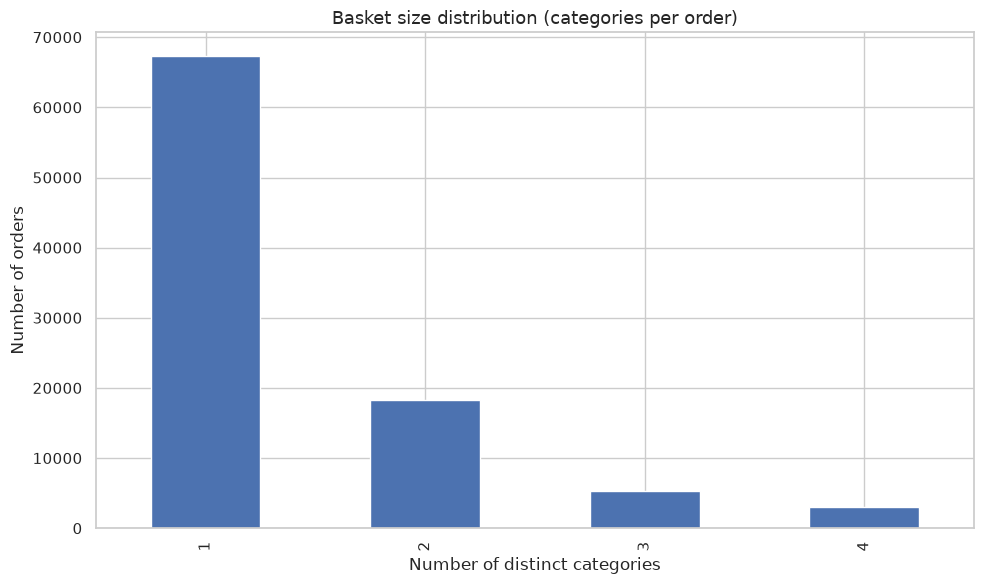

In [3]:
# Build one basket per order = set of distinct categories
baskets = (items_clean.groupby("order_id")["category"]
           .apply(lambda s: sorted(set(s))))

basket_sizes = baskets.apply(len)
n_orders = len(baskets)

print(f"Total orders:                  {n_orders:,}")
print(f"Avg. categories per order:     {basket_sizes.mean():.2f}")
print(f"Orders with >=2 categories:    {(basket_sizes >= 2).sum():,} "
      f"({(basket_sizes >= 2).mean():.1%})")

# Distribution of basket sizes
ax = basket_sizes.value_counts().sort_index().plot(kind="bar", color="#4C72B0")
ax.set_title("Basket size distribution (categories per order)")
ax.set_xlabel("Number of distinct categories")
ax.set_ylabel("Number of orders")
plt.tight_layout(); plt.show()

4. Category Frequencies & Support

Count how often each category appears across orders (single-item support) and
how often each category pair co-occurs (pair support). These counts are the
basis for the association rules. Pairs are taken from sorted baskets so each
pair is always stored in a consistent order.

/opt/conda/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregator, agg_var)


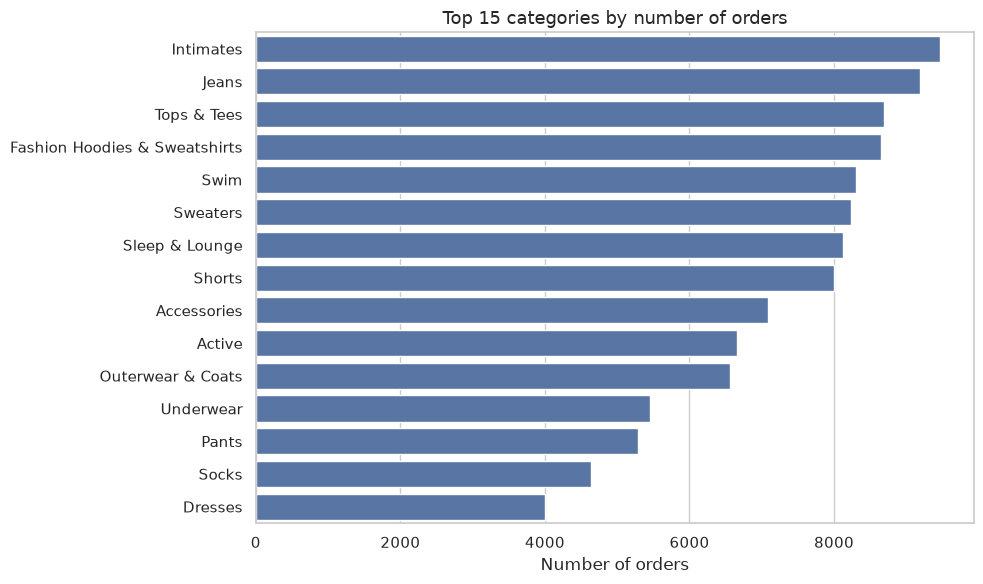

,category,orders,support
14,Intimates,9463,0.100577
2,Jeans,9193,0.097707
18,Tops & Tees,8688,0.092340
9,Fashion Hoodies & Sweatshirts,8655,0.091989
6,Swim,8310,0.088323
7,Sweaters,8232,0.087493
5,Sleep & Lounge,8118,0.086282
17,Shorts,8005,0.085081
8,Accessories,7087,0.075324
0,Active,6652,0.070701


In [5]:
# Count single-category and pairwise co-occurrence frequencies
baskets_list = baskets.tolist()

item_counts = Counter()
pair_counts = Counter()
for b in baskets_list:
    for c in b:
        item_counts[c] += 1
    # b is sorted -> pairs always in a consistent (alphabetical) order
    for pair in combinations(b, 2):
        pair_counts[pair] += 1

# Support per category = share of orders containing it
support = pd.DataFrame({
    "category": list(item_counts.keys()),
    "orders":   list(item_counts.values()),
}).sort_values("orders", ascending=False)
support["support"] = support["orders"] / n_orders

# Plot top categories
top = support.head(15)
ax = sns.barplot(data=top, y="category", x="orders", color="#4C72B0")
ax.set_title("Top 15 categories by number of orders")
ax.set_xlabel("Number of orders"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

support.head(15)

5. Generate Association Rules

For every category pair we build both directed rules (A -> B and B -> A) and
compute support, confidence and lift:

- **support(A,B)** = share of orders containing both
- **confidence(A->B)** = support(A,B) / support(A) = P(B | A)
- **lift(A->B)** = confidence(A->B) / support(B); lift > 1 means the two occur
  together more often than expected under independence

`min_support` and `min_pair_count` filter out rare pairs so the rules stay
statistically reliable.

In [6]:
# Build directed association rules (A -> B) at category level
def build_rules(item_counts, pair_counts, n_orders, min_support=0.0005, min_pair_count=20):
    """Generate directed association rules (A -> B) at category level."""
    rows = []
    for (a, b), c_ab in pair_counts.items():
        if c_ab < min_pair_count:
            continue
        sup_ab = c_ab / n_orders
        if sup_ab < min_support:
            continue
        sup_a = item_counts[a] / n_orders
        sup_b = item_counts[b] / n_orders
        # both directions
        for ante, cons, sup_ante, sup_cons in [(a, b, sup_a, sup_b),
                                               (b, a, sup_b, sup_a)]:
            conf = sup_ab / sup_ante
            lift = conf / sup_cons
            rows.append({
                "antecedent": ante, "consequent": cons,
                "pair_orders": c_ab,
                "support": sup_ab,
                "confidence": conf,
                "lift": lift,
            })
    rules = pd.DataFrame(rows)
    return rules.sort_values("lift", ascending=False).reset_index(drop=True)

rules = build_rules(item_counts, pair_counts, n_orders,
                    min_support=0.0005, min_pair_count=20)
print(f"Number of generated rules: {len(rules)}")

# Top 20 rules by lift (rounded, no jinja2/.style needed)
rules.head(20).round({"support": 4, "confidence": 3, "lift": 2})

Number of generated rules: 436


,antecedent,consequent,pair_orders,support,confidence,lift
0,Dresses,Skirts,107,0.0011,0.027,1.57
1,Skirts,Dresses,107,0.0011,0.067,1.57
2,Leggings,Blazers & Jackets,87,0.0009,0.037,1.46
3,Blazers & Jackets,Leggings,87,0.0009,0.037,1.46
4,Leggings,Skirts,58,0.0006,0.025,1.44
5,Skirts,Leggings,58,0.0006,0.036,1.44
6,Dresses,Socks & Hosiery,169,0.0018,0.042,1.41
7,Socks & Hosiery,Dresses,169,0.0018,0.060,1.41
8,Skirts,Plus,76,0.0008,0.047,1.41
9,Plus,Skirts,76,0.0008,0.024,1.41


6. Top Rules as Bar Charts

Two side-by-side views: the strongest rules by lift (strength of association)
and by confidence (likelihood of B given A). The dashed line marks lift = 1
(no association).

/opt/conda/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregator, agg_var)
/opt/conda/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregator, agg_var)


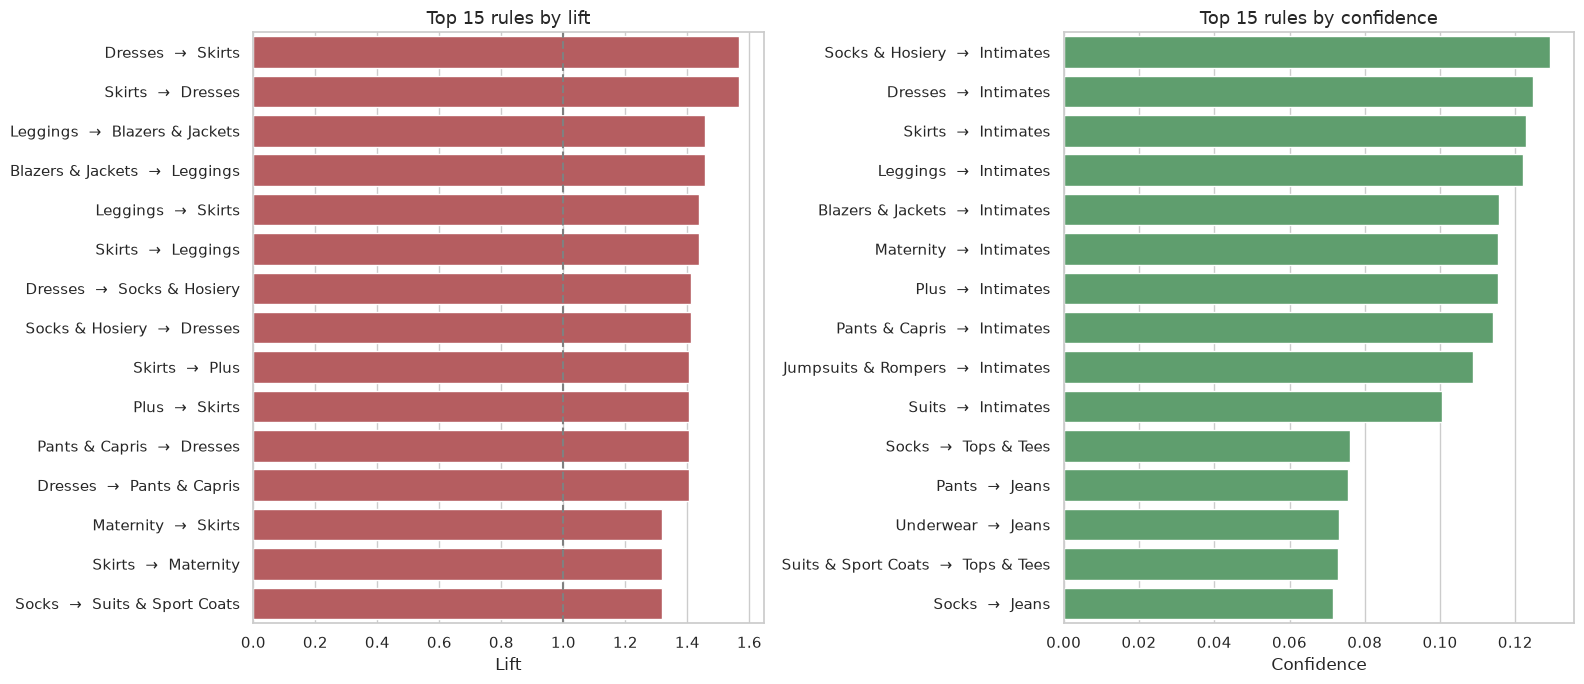

In [7]:
# Visualize top rules by lift and by confidence
topn = rules.head(15).copy()
topn["rule"] = topn["antecedent"] + "  →  " + topn["consequent"]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.barplot(data=topn, y="rule", x="lift", color="#C44E52", ax=axes[0])
axes[0].set_title("Top 15 rules by lift"); axes[0].set_xlabel("Lift"); axes[0].set_ylabel("")
axes[0].axvline(1, color="grey", ls="--")  # lift = 1 -> no association

conf_top = rules.sort_values("confidence", ascending=False).head(15).copy()
conf_top["rule"] = conf_top["antecedent"] + "  →  " + conf_top["consequent"]
sns.barplot(data=conf_top, y="rule", x="confidence", color="#55A868", ax=axes[1])
axes[1].set_title("Top 15 rules by confidence"); axes[1].set_xlabel("Confidence"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()